*Nama: Hafizh Ikhwanul Muslim*

*NIM: 2411512022*

*Jurusan: Teknik Komputer Kelas B*

In [1]:
# Persiapan library yang digunakan di seluruh notebook
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd

plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11
print("Library siap digunakan.")

Library siap digunakan.


1. Modifikasi `packet_loss_prob` pada simulasi Perception $\rightarrow$ Network $\rightarrow$ Application menjadi `0.3`. Amati dan jelaskan dampaknya terhadap jumlah data yang sampai ke *Application Layer*.

In [2]:
# Definisi kelas 3 Lapisan Arsitektur IoT (Perception -> Network -> Application)
class PerceptionLayer:
    # Mensimulasikan sensor suhu (DHT22-like) yang membaca data lingkungan.
    def __init__(self, suhu_dasar=28.0):
        self.suhu_dasar = suhu_dasar

    def baca_sensor(self):
        # Simulasi noise sensor + variasi suhu ruangan
        noise = random.uniform(-1.5, 1.5)
        suhu = round(self.suhu_dasar + noise, 2)
        return {"sensor": "DHT22", "suhu_celsius": suhu, "timestamp": time.time()}


class NetworkLayer:
    # Mensimulasikan transmisi data melalui jaringan (mis. WiFi + MQTT).
    def __init__(self, packet_loss_prob=0.05):
        self.packet_loss_prob = packet_loss_prob

    def kirim(self, payload):
        if random.random() < self.packet_loss_prob:
            return None  # paket hilang, mensimulasikan ketidakandalan jaringan
        # Simulasi payload terbungkus MQTT topic
        return {"topic": "kampus/ruang301/suhu", "payload": payload}


class ApplicationLayer:
    # Mensimulasikan pemrosesan data & alert di dashboard/cloud.
    def __init__(self, ambang_batas=30.0):
        self.ambang_batas = ambang_batas
        self.riwayat = []
        self.siklus_berhasil = []
        self.jumlah_hilang = 0

    def proses(self, pesan, siklus=None):
        if pesan is None:
            self.jumlah_hilang += 1
            print("  [APPLICATION] Data tidak diterima (packet loss di Network Layer).")
            return
        suhu = pesan["payload"]["suhu_celsius"]
        self.riwayat.append(suhu)
        if siklus is not None:
            self.siklus_berhasil.append(siklus)
        status = "NORMAL"
        if suhu > self.ambang_batas:
            status = "ALERT! Suhu melebihi ambang batas"
        print(f"  [APPLICATION] Topic={pesan['topic']} | Suhu={suhu}°C | Status={status}")


# --- Menjalankan simulasi 10 siklus pembacaan dengan packet_loss_prob = 0.3 ---
random.seed(42)  # Seed tetap agar hasil pengamatan konsisten dan dapat direproduksi
sensor = PerceptionLayer(suhu_dasar=29.0)
jaringan = NetworkLayer(packet_loss_prob=0.3)  # Dimodifikasi menjadi 0.3 (30%)
aplikasi = ApplicationLayer(ambang_batas=30.5)

semua_pembacaan_sensor = []

print("=== SIMULASI ALUR DATA: PERCEPTION -> NETWORK -> APPLICATION (packet_loss_prob = 0.3) ===\n")
for siklus in range(1, 11):
    print(f"Siklus {siklus}:")
    data_mentah = sensor.baca_sensor()
    semua_pembacaan_sensor.append(data_mentah['suhu_celsius'])
    print(f"  [PERCEPTION]  Sensor membaca suhu = {data_mentah['suhu_celsius']}°C")

    paket = jaringan.kirim(data_mentah)
    aplikasi.proses(paket, siklus=siklus)
    print()

print(f"Total data yang berhasil sampai ke Application Layer: {len(aplikasi.riwayat)} dari 10 pembacaan")
print(f"Total paket hilang (packet loss) di Network Layer   : {aplikasi.jumlah_hilang} dari 10 pembacaan ({aplikasi.jumlah_hilang/10*100:.0f}%)")

=== SIMULASI ALUR DATA: PERCEPTION -> NETWORK -> APPLICATION (packet_loss_prob = 0.3) ===

Siklus 1:
  [PERCEPTION]  Sensor membaca suhu = 29.42°C
  [APPLICATION] Data tidak diterima (packet loss di Network Layer).

Siklus 2:
  [PERCEPTION]  Sensor membaca suhu = 28.33°C
  [APPLICATION] Data tidak diterima (packet loss di Network Layer).

Siklus 3:
  [PERCEPTION]  Sensor membaca suhu = 29.71°C
  [APPLICATION] Topic=kampus/ruang301/suhu | Suhu=29.71°C | Status=NORMAL

Siklus 4:
  [PERCEPTION]  Sensor membaca suhu = 30.18°C
  [APPLICATION] Data tidak diterima (packet loss di Network Layer).

Siklus 5:
  [PERCEPTION]  Sensor membaca suhu = 28.77°C
  [APPLICATION] Data tidak diterima (packet loss di Network Layer).

Siklus 6:
  [PERCEPTION]  Sensor membaca suhu = 28.16°C
  [APPLICATION] Topic=kampus/ruang301/suhu | Suhu=28.16°C | Status=NORMAL

Siklus 7:
  [PERCEPTION]  Sensor membaca suhu = 27.58°C
  [APPLICATION] Data tidak diterima (packet loss di Network Layer).

Siklus 8:
  [PERCEPTIO

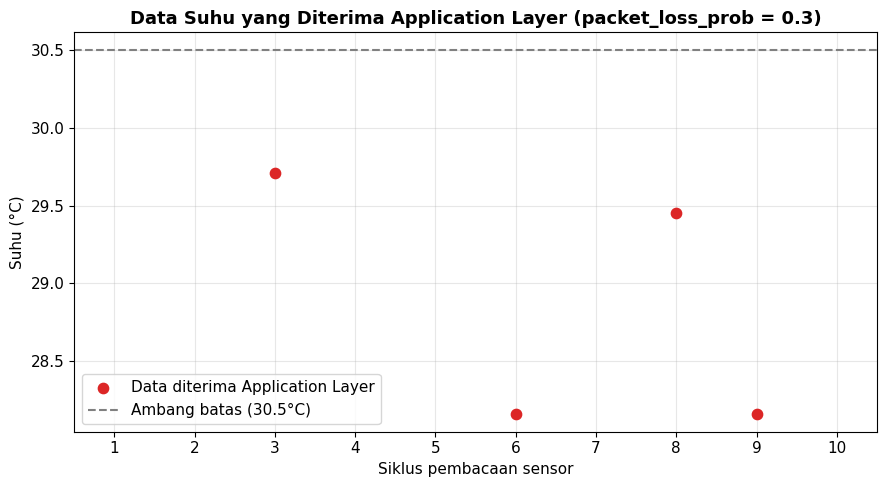

In [3]:
# Visualisasi suhu yang benar-benar sampai ke Application Layer pada siklus aslinya
if aplikasi.riwayat:
    fig, ax = plt.subplots()
    # Titik hanya ditampilkan untuk siklus yang berhasil; siklus hilang tampak sebagai celah.
    ax.scatter(aplikasi.siklus_berhasil, aplikasi.riwayat, color='#dc2626', s=55,
               label='Data diterima Application Layer', zorder=3)
    ax.axhline(y=aplikasi.ambang_batas, color='gray', linestyle='--',
               label=f'Ambang batas ({aplikasi.ambang_batas}°C)')
    ax.set_title('Data Suhu yang Diterima Application Layer (packet_loss_prob = 0.3)',
                 fontsize=13, fontweight='bold')
    ax.set_xlabel('Siklus pembacaan sensor')
    ax.set_ylabel('Suhu (°C)')
    ax.set_xticks(range(1, 11))
    ax.set_xlim(0.5, 10.5)
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print('Tidak ada data yang berhasil diterima, jalankan ulang sel simulasi.')


Penjelasan:

1. **Jumlah data yang sampai ke *Application Layer*.**
   - Nilai `packet_loss_prob = 0.3` berarti peluang satu paket hilang adalah 30%, sedangkan peluang berhasil terkirim adalah 70%.
   - Dengan `random.seed(42)`, hasil 10 siklus pada notebook ini adalah **4 data diterima (40%)** dan **6 paket hilang (60%)**. Paket hilang terjadi pada siklus 1, 2, 4, 5, 7, dan 10.
   - Hasil 6 paket hilang tidak berarti nilai probabilitasnya salah. Untuk 10 percobaan saja, hasil acak dapat menyimpang dari persentase teoritis. Secara rata-rata, dari 10 pengiriman diperkirakan sekitar `10 × 0.3 = 3` paket hilang dan 7 paket diterima.

2. **Kekosongan data (*blind spot*).**
   - Karena beberapa paket tidak sampai, *Application Layer* tidak memperoleh pembacaan suhu pada siklus yang hilang. Pada hasil ini ada kehilangan beruntun di siklus 1–2 dan 4–5.
   - Grafik menggunakan nomor siklus sensor sebenarnya, bukan nomor urut data yang diterima, sehingga celah pada waktu pengukuran tidak disamarkan.

3. **Risiko peringatan yang terlewat.**
   - Ambang batas simulasi mengikuti contoh modul, yaitu **30,5°C**. Jika pembacaan yang seharusnya memicu peringatan hilang di jaringan, *Application Layer* tidak bisa memproses pembacaan itu atau mengeluarkan peringatan berdasarkan data tersebut.

4. **Upaya mitigasi.**
   - Dalam rancangan nyata, kehilangan paket bisa ditangani dengan mekanisme pengiriman ulang (*retry*), penyimpanan sementara (*buffer*) di perangkat, dan pengaturan keandalan komunikasi yang sesuai. Jika MQTT digunakan, QoS perlu dipilih sesuai jalur komunikasi; QoS tidak otomatis memperbaiki setiap gangguan pada semua bagian jaringan.


2. Pada simulasi *power budgeting*, coba ubah `arus_active_mA` menjadi nilai perangkat WiFi (mis. `120 mA`) dan bandingkan hasilnya dengan BLE (mis. `15 mA`). Apa implikasinya terhadap pemilihan protokol jaringan (akan dibahas di Pertemuan 4)?

In [4]:
# Simulasi Power Budgeting: Perbandingan WiFi (120 mA) vs BLE (15 mA)
kapasitas_baterai_mAh = 2000   # baterai Li-ion 2000 mAh
arus_wifi_active_mA = 120      # arus saat mikrokontroler + radio WiFi aktif (mA)
arus_ble_active_mA = 15        # arus saat mikrokontroler + radio BLE aktif (mA)
arus_sleep_mA = 0.01           # arus saat deep sleep (mA) - sangat kecil
durasi_active_detik = 2        # lama transmisi tiap siklus (detik)

def estimasi_umur_baterai_jam(interval_kirim_detik, arus_active_mA):
    duty_cycle = durasi_active_detik / interval_kirim_detik
    arus_rata_rata_mA = (duty_cycle * arus_active_mA) + ((1 - duty_cycle) * arus_sleep_mA)
    umur_jam = kapasitas_baterai_mAh / arus_rata_rata_mA
    return umur_jam, arus_rata_rata_mA

interval_list_detik = [2, 10, 30, 60, 300, 900, 3600]
label_interval = ['2 dtk\n(always-on)', '10 dtk', '30 dtk', '1 menit', '5 menit', '15 menit', '1 jam']
label_tabel = ['2 dtk (always-on)', '10 dtk', '30 dtk', '1 menit', '5 menit', '15 menit', '1 jam']

umur_wifi_hari, arus_wifi_list = [], []
umur_ble_hari, arus_ble_list = [], []

for interval in interval_list_detik:
    u_wifi_jam, a_wifi = estimasi_umur_baterai_jam(interval, arus_wifi_active_mA)
    u_ble_jam, a_ble = estimasi_umur_baterai_jam(interval, arus_ble_active_mA)
    umur_wifi_hari.append(u_wifi_jam / 24)
    arus_wifi_list.append(a_wifi)
    umur_ble_hari.append(u_ble_jam / 24)
    arus_ble_list.append(a_ble)

df_power = pd.DataFrame({
    'Interval Kirim': label_tabel,
    'Arus Rata2 WiFi (mA)': [round(a, 3) for a in arus_wifi_list],
    'Umur Baterai WiFi (hari)': [round(u, 1) for u in umur_wifi_hari],
    'Arus Rata2 BLE (mA)': [round(a, 3) for a in arus_ble_list],
    'Umur Baterai BLE (hari)': [round(u, 1) for u in umur_ble_hari],
    'Rasio (BLE vs WiFi)': [f"{(b / w):.2f}x" for w, b in zip(umur_wifi_hari, umur_ble_hari)]
})

print("=== TABEL PERBANDINGAN POWER BUDGETING: WiFi (120 mA) vs BLE (15 mA) ===")
print(df_power.to_string(index=False))

=== TABEL PERBANDINGAN POWER BUDGETING: WiFi (120 mA) vs BLE (15 mA) ===
   Interval Kirim  Arus Rata2 WiFi (mA)  Umur Baterai WiFi (hari)  Arus Rata2 BLE (mA)  Umur Baterai BLE (hari) Rasio (BLE vs WiFi)
2 dtk (always-on)               120.000                       0.7               15.000                      5.6               8.00x
           10 dtk                24.008                       3.5                3.008                     27.7               7.98x
           30 dtk                 8.009                      10.4                1.009                     82.6               7.94x
          1 menit                 4.010                      20.8                0.510                    163.5               7.87x
          5 menit                 0.810                     102.9                0.110                    758.0               7.37x
         15 menit                 0.277                     301.2                0.043                   1924.1               6.39x
   

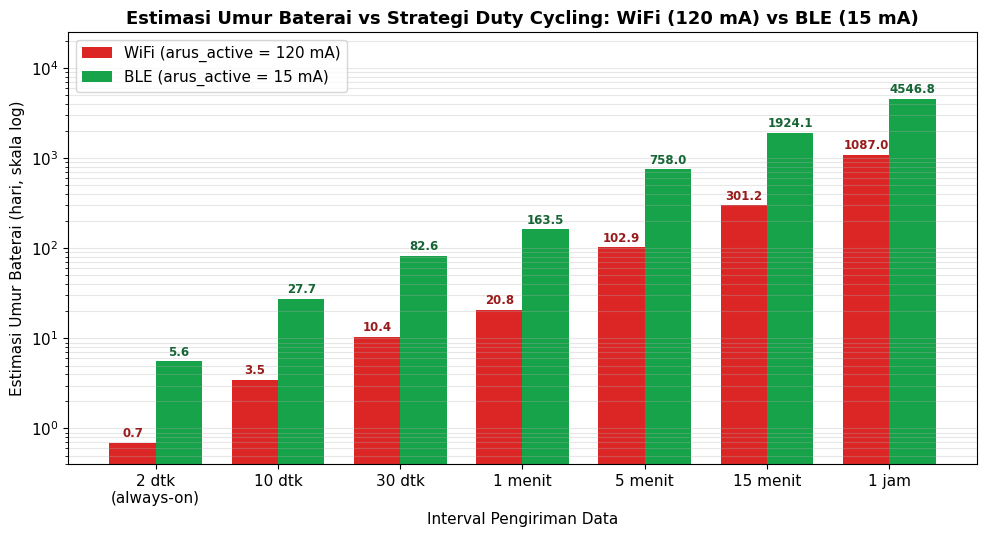


Kesimpulan: Pada interval kirim 1 menit, perangkat BLE bertahan ~163.5 hari dibandingkan WiFi yang hanya bertahan ~20.8 hari.
Pada interval kirim 1 jam, perangkat BLE bertahan ~4546.8 hari (~12.5 tahun) sedangkan WiFi bertahan ~1087.0 hari (~3.0 tahun).


In [5]:
# Visualisasi Perbandingan Umur Baterai: WiFi (120 mA) vs BLE (15 mA)
x = np.arange(len(label_interval))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 5.5))
bars_wifi = ax.bar(x - width/2, umur_wifi_hari, width, label='WiFi (arus_active = 120 mA)', color='#dc2626')
bars_ble = ax.bar(x + width/2, umur_ble_hari, width, label='BLE (arus_active = 15 mA)', color='#16a34a')

for bar, nilai in zip(bars_wifi, umur_wifi_hari):
    ax.annotate(f'{nilai:.1f}', (bar.get_x() + bar.get_width()/2, bar.get_height()),
                textcoords="offset points", xytext=(0, 4), ha='center', fontsize=8.5, color='#991b1b', fontweight='bold')

for bar, nilai in zip(bars_ble, umur_ble_hari):
    ax.annotate(f'{nilai:.1f}', (bar.get_x() + bar.get_width()/2, bar.get_height()),
                textcoords="offset points", xytext=(0, 4), ha='center', fontsize=8.5, color='#166534', fontweight='bold')

ax.set_yscale('log')
ax.set_ylim(0.4, 25000)
ax.set_xticks(x)
ax.set_xticklabels(label_interval)
ax.set_title('Estimasi Umur Baterai vs Strategi Duty Cycling: WiFi (120 mA) vs BLE (15 mA)', fontsize=13, fontweight='bold')
ax.set_xlabel('Interval Pengiriman Data')
ax.set_ylabel('Estimasi Umur Baterai (hari, skala log)')
ax.legend()
ax.grid(axis='y', which='both', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nKesimpulan: Pada interval kirim 1 menit, perangkat BLE bertahan ~{umur_ble_hari[3]:.1f} hari "
      f"dibandingkan WiFi yang hanya bertahan ~{umur_wifi_hari[3]:.1f} hari.")
print(f"Pada interval kirim 1 jam, perangkat BLE bertahan ~{umur_ble_hari[-1]:.1f} hari (~{umur_ble_hari[-1]/365:.1f} tahun) "
      f"sedangkan WiFi bertahan ~{umur_wifi_hari[-1]:.1f} hari (~{umur_wifi_hari[-1]/365:.1f} tahun).")

Penjelasan:

1. **Perbandingan estimasi umur baterai (WiFi 120 mA vs BLE 15 mA).**
   - Pada mode *always-on* (interval 2 detik, tanpa waktu tidur), estimasi umur baterai adalah sekitar **0,7 hari untuk WiFi** dan **5,6 hari untuk BLE**.
   - Pada interval pengiriman 1 menit, estimasi menjadi **20,8 hari untuk WiFi** dan **163,5 hari untuk BLE**, atau sekitar **7,87 kali** lebih lama untuk BLE pada parameter simulasi ini.
   - Pada interval 1 jam, hasil kode adalah sekitar **1.087,0 hari (3,0 tahun) untuk WiFi** dan **4.546,8 hari (12,5 tahun) untuk BLE**. Rasio turun menjadi sekitar **4,18 kali**, karena arus *deep sleep* (`0,01 mA`) menjadi bagian besar dari arus rata-rata BLE: kontribusi arus aktif BLE hanya `15 × (2/3600) ≈ 0,0083 mA`, sebanding dengan arus tidur.
   - Ini adalah **estimasi matematis ideal**, bukan jaminan umur baterai di lapangan. Model belum memperhitungkan konsumsi radio nyata ketika tersambung, kualitas sinyal, efisiensi regulator, perubahan kapasitas baterai, dan konsumsi komponen lain.

2. **Implikasi terhadap pemilihan protokol jaringan.**
   - **BLE** cocok dipertimbangkan untuk sensor yang mengirim data kecil dengan jarak relatif pendek dan mengutamakan konsumsi daya rendah. Untuk meneruskan data ke internet, sistem biasanya membutuhkan perangkat perantara/gateway.
   - **WiFi** cocok ketika tersedia suplai daya yang memadai atau ketika perangkat memerlukan bandwidth tinggi dan koneksi jaringan lokal yang tersedia. Pada perangkat baterai, memperpanjang interval pengiriman dan menggunakan *duty cycling* dapat mengurangi konsumsi daya.
   - Karena angka arus 120 mA dan 15 mA adalah asumsi simulasi tugas, keputusan nyata sebaiknya memakai pengukuran atau spesifikasi perangkat yang akan digunakan.


3. Pilih satu *use case* IoT (*smart home* / *smart city* / *industri*) dan petakan komponennya ke dalam 3 lapisan arsitektur (*Perception–Network–Application*) dalam bentuk tabel atau diagram.

Use Case yang dipilih: **Smart City — Sistem Peringatan Dini Banjir & Pemantauan Drainase Perkotaan (*Smart Flood Early Warning System*)**

Sistem ini ditempatkan di Daerah Aliran Sungai (DAS) dan pintu air utama kota untuk memantau tinggi muka air, curah hujan, serta laju aliran air secara *real-time*, mengaktifkan sirine/pintu air otomatis saat kritis, serta menyiarkan peringatan dini kepada BPBD dan masyarakat.

In [6]:
# Tabel Pemetaan Komponen Use Case Smart Flood Early Warning System ke 3 Lapisan Arsitektur IoT
data_arsitektur = [
    {
        "Lapisan Arsitektur": "1. Perception Layer",
        "Komponen Utama": (
            "Sensor Ultrasonik Tahan Air (JSN-SR04T), Tipping Bucket Rain Gauge, "
            "Water Flow Sensor, Mikrokontroler ESP32/STM32L4 (Solar + LiFePO4), "
            "Aktuator Motor Pintu Air & Sirine Lokal"
        ),
        "Protokol / Antarmuka Lokal": "GPIO, ADC, Pulse Counter, UART/I2C, PWM, Deep Sleep Duty Cycling",
        "Fungsi & Peran dalam Sistem": (
            "Mengukur tinggi muka air (cm), curah hujan (mm/jam), dan debit aliran air; "
            "mengeksekusi buka/tutup pintu air serta membunyikan sirine saat kondisi bahaya."
        )
    },
    {
        "Lapisan Arsitektur": "2. Network Layer",
        "Komponen Utama": (
            "Modul Transceiver LoRa (SX1276), Outdoor LoRaWAN Gateway, "
            "Modem Backhaul 4G LTE / Fiber Optik Kota, Cloud MQTT Broker (Mosquitto/EMQX)"
        ),
        "Protokol / Antarmuka Lokal": "LoRaWAN (Sub-GHz), TCP/IP, MQTT over TLS (QoS 1)",
        "Fungsi & Peran dalam Sistem": (
            "Mengirimkan paket telemetri dari pos sungai ke gateway jarak jauh dengan daya rendah, "
            "lalu meneruskan data ke server cloud dan mengirimkan perintah balik (downlink) ke aktuator."
        )
    },
    {
        "Lapisan Arsitektur": "3. Application Layer",
        "Komponen Utama": (
            "Time-Series Database (InfluxDB), Layanan Pemrosesan & Rule Engine (Node-RED / Python Backend), "
            "Web Dashboard GIS BPBD (Grafana), Bot Notifikasi Publik (Telegram / SMS / Aplikasi Mobile)"
        ),
        "Protokol / Antarmuka Lokal": "HTTPS, WebSocket, REST API, Flux/SQL Query",
        "Fungsi & Peran dalam Sistem": (
            "Menyimpan data historis, menganalisis tren kenaikan air (Normal/Waspada/Siaga/Awas), "
            "menampilkan peta pemantauan real-time, dan mengirim peringatan dini otomatis ke warga."
        )
    }
]

df_usecase = pd.DataFrame(data_arsitektur)
print("=== TABEL PEMETAAN 3 LAPISAN ARSITEKTUR: SMART FLOOD EARLY WARNING SYSTEM ===\n")
for idx, row in df_usecase.iterrows():
    print(f"[{row['Lapisan Arsitektur']}]")
    print(f"  • Komponen : {row['Komponen Utama']}")
    print(f"  • Protokol : {row['Protokol / Antarmuka Lokal']}")
    print(f"  • Fungsi   : {row['Fungsi & Peran dalam Sistem']}\n")

=== TABEL PEMETAAN 3 LAPISAN ARSITEKTUR: SMART FLOOD EARLY WARNING SYSTEM ===

[1. Perception Layer]
  • Komponen : Sensor Ultrasonik Tahan Air (JSN-SR04T), Tipping Bucket Rain Gauge, Water Flow Sensor, Mikrokontroler ESP32/STM32L4 (Solar + LiFePO4), Aktuator Motor Pintu Air & Sirine Lokal
  • Protokol : GPIO, ADC, Pulse Counter, UART/I2C, PWM, Deep Sleep Duty Cycling
  • Fungsi   : Mengukur tinggi muka air (cm), curah hujan (mm/jam), dan debit aliran air; mengeksekusi buka/tutup pintu air serta membunyikan sirine saat kondisi bahaya.

[2. Network Layer]
  • Komponen : Modul Transceiver LoRa (SX1276), Outdoor LoRaWAN Gateway, Modem Backhaul 4G LTE / Fiber Optik Kota, Cloud MQTT Broker (Mosquitto/EMQX)
  • Protokol : LoRaWAN (Sub-GHz), TCP/IP, MQTT over TLS (QoS 1)
  • Fungsi   : Mengirimkan paket telemetri dari pos sungai ke gateway jarak jauh dengan daya rendah, lalu meneruskan data ke server cloud dan mengirimkan perintah balik (downlink) ke aktuator.

[3. Application Layer]
  • Komp

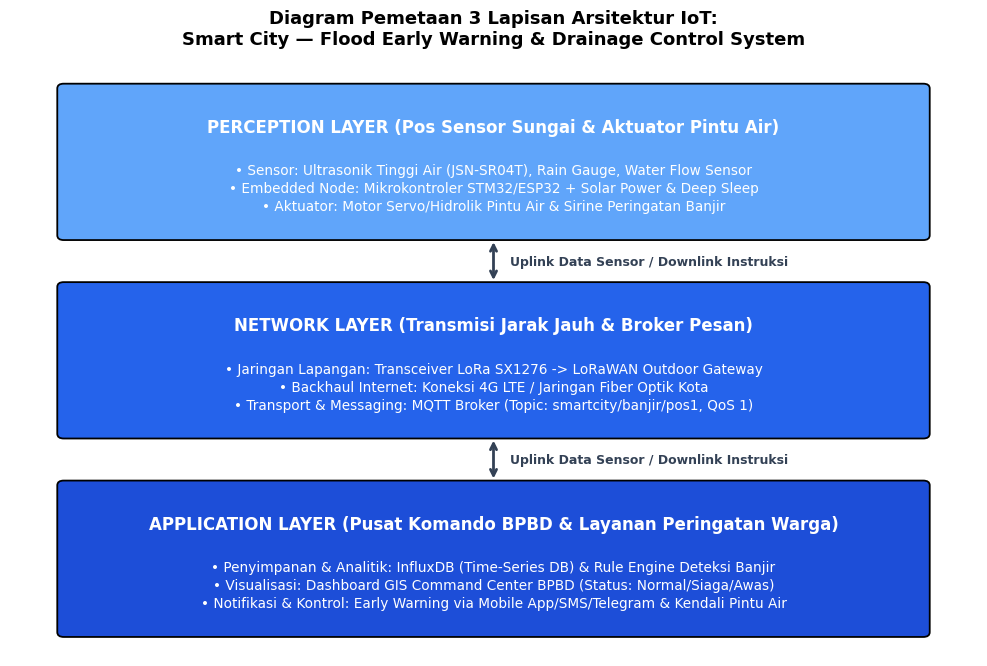

In [7]:
# Visualisasi Diagram 3 Lapisan Arsitektur IoT untuk Use Case Smart Flood Early Warning System
fig, ax = plt.subplots(figsize=(10, 6.8))

layers = [
    (
        "APPLICATION LAYER (Pusat Komando BPBD & Layanan Peringatan Warga)",
        "• Penyimpanan & Analitik: InfluxDB (Time-Series DB) & Rule Engine Deteksi Banjir\n"
        "• Visualisasi: Dashboard GIS Command Center BPBD (Status: Normal/Siaga/Awas)\n"
        "• Notifikasi & Kontrol: Early Warning via Mobile App/SMS/Telegram & Kendali Pintu Air",
        "#1d4ed8"
    ),
    (
        "NETWORK LAYER (Transmisi Jarak Jauh & Broker Pesan)",
        "• Jaringan Lapangan: Transceiver LoRa SX1276 -> LoRaWAN Outdoor Gateway\n"
        "• Backhaul Internet: Koneksi 4G LTE / Jaringan Fiber Optik Kota\n"
        "• Transport & Messaging: MQTT Broker (Topic: smartcity/banjir/pos1, QoS 1)",
        "#2563eb"
    ),
    (
        "PERCEPTION LAYER (Pos Sensor Sungai & Aktuator Pintu Air)",
        "• Sensor: Ultrasonik Tinggi Air (JSN-SR04T), Rain Gauge, Water Flow Sensor\n"
        "• Embedded Node: Mikrokontroler STM32/ESP32 + Solar Power & Deep Sleep\n"
        "• Aktuator: Motor Servo/Hidrolik Pintu Air & Sirine Peringatan Banjir",
        "#60a5fa"
    ),
]

y = 0
height = 1.85
gap = 0.65

for i, (title, desc, color) in enumerate(layers):
    rect = mpatches.FancyBboxPatch((0, y), 8, height, boxstyle="round,pad=0.06",
                                   facecolor=color, edgecolor='black', linewidth=1.3)
    ax.add_patch(rect)
    ax.text(4, y + height*0.74, title, ha='center', va='center', fontsize=12,
            fontweight='bold', color='white')
    ax.text(4, y + height*0.32, desc, ha='center', va='center', fontsize=9.8,
            color='white', linespacing=1.35)

    if i < len(layers) - 1:
        y_top = y + height
        ax.annotate('', xy=(4, y_top + gap - 0.05), xytext=(4, y_top + 0.05),
                    arrowprops=dict(arrowstyle='<->', lw=2.0, color='#334155'))
        ax.text(4.15, y_top + gap/2, 'Uplink Data Sensor / Downlink Instruksi',
                va='center', ha='left', fontsize=9, color='#334155', fontweight='bold')
    y += height + gap

ax.set_xlim(-0.5, 8.5)
ax.set_ylim(-0.3, y - gap + 0.3)
ax.axis('off')
ax.set_title('Diagram Pemetaan 3 Lapisan Arsitektur IoT:\nSmart City — Flood Early Warning & Drainage Control System',
             fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

Tabel pemetaan komponen (*Smart Flood Early Warning System*):

| Lapisan Arsitektur | Komponen Perangkat Keras & Lunak | Protokol & Teknologi | Output Data / Aksi Sistem |
| :--- | :--- | :--- | :--- |
| **Perception Layer** | • Sensor Ultrasonik `JSN-SR04T` (Tinggi Air)<br>• *Tipping Bucket Rain Gauge* (Curah Hujan)<br>• *Water Flow Sensor* (Kecepatan Aliran)<br>• MCU `STM32L4` / `ESP32` + Panel Surya<br>• Aktuator Motor Pintu Air & Sirine | GPIO, ADC, UART/I2C, Interrupt, PWM, *Duty Cycling* | Pembacaan fisik ketinggian air (`cm`), intensitas hujan (`mm/jam`), debit aliran (`L/menit`), serta aksi fisik pembukaan pintu air & bunyi sirine lokal |
| **Network Layer** | • Modul Radio `LoRa SX1276`<br>• *LoRaWAN Multi-Channel Gateway*<br>• Router Backhaul 4G LTE / Fiber Optik<br>• *Cloud MQTT Broker* (`EMQX`/`Mosquitto`) | LoRaWAN (920–923 MHz), TCP/IP, TLS/SSL, MQTT (QoS 1) | Transmisi paket *payload* JSON pada topik `smartcity/banjir/pos01/telemetry` (uplink) dan `.../actuator/cmd` (downlink) |
| **Application Layer** | • *Time-Series Database* (`InfluxDB`)<br>• *Rule Engine* & Analitik (`Node-RED`)<br>• *Web Dashboard* GIS BPBD (`Grafana`)<br>• Bot Telegram, SMS Broadcast & *Mobile App* | HTTPS, REST API, WebSocket, Flux/SQL Query | Grafik dan peta pemantauan banjir *real-time*, klasifikasi status siaga (*Normal/Waspada/Siaga/Awas*), *alert* otomatis ke warga, serta komando jarak jauh ke pintu air |